<a href="https://colab.research.google.com/github/jayyadav-000/Breast-Cancer-Detection/blob/main/hands_on_lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name:- Jay Yadav

Roll no:- betn1ai25139

SEC:- E

In [340]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as mtb
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_auc_score

In [341]:
df = pd.read_csv("/data.csv")

TASK **1**

In [342]:
df.head(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,NaN


In [343]:
df.tail(10)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
559,925291,B,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,...,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,NaN
560,925292,B,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,...,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,NaN
561,925311,B,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,...,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,NaN
562,925622,M,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,...,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,NaN
563,926125,M,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,...,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,NaN
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,NaN


In [344]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [345]:
display(df.describe())

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [346]:
print(df.isnull().sum())

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [347]:
df.shape

(569, 33)

In [348]:
df = df.drop(columns = ['id', 'Unnamed: 32'], errors = 'ignore')

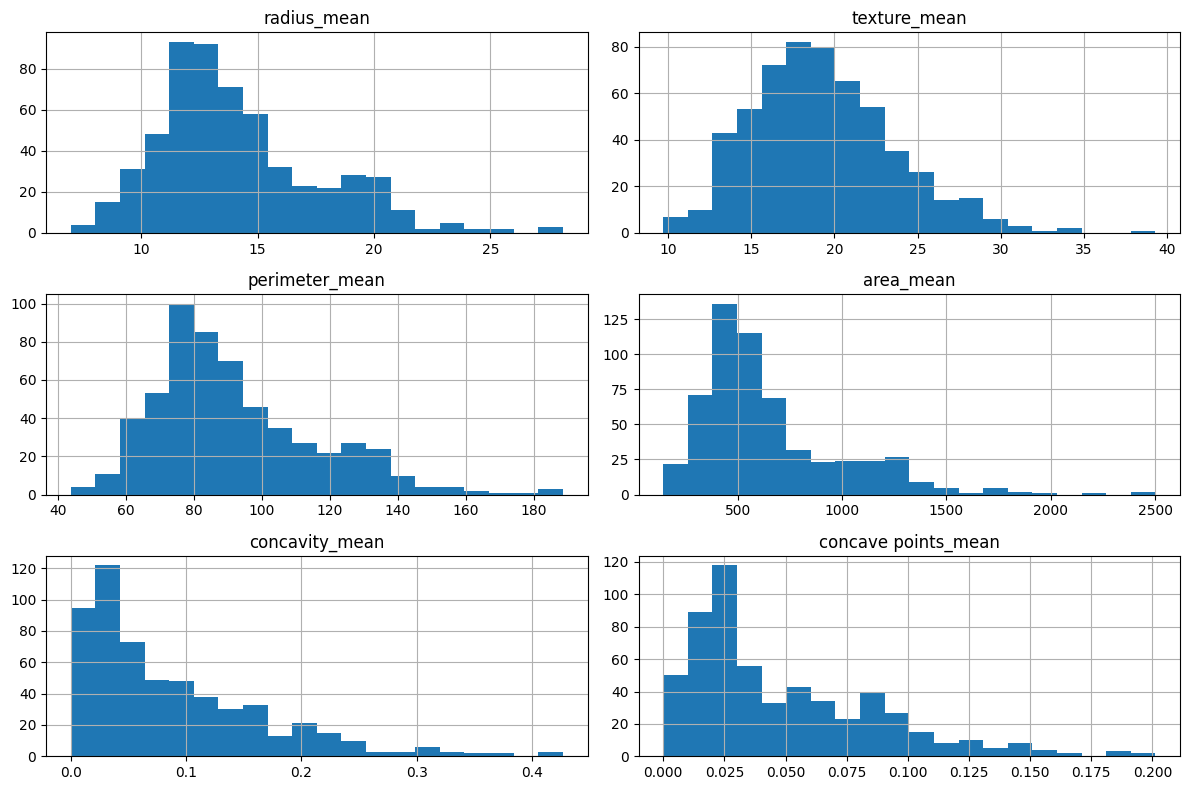

In [349]:
# Histogram
cols = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean']

df[cols].hist(figsize = (12, 8), bins = 20)
mtb.tight_layout()
mtb.show()

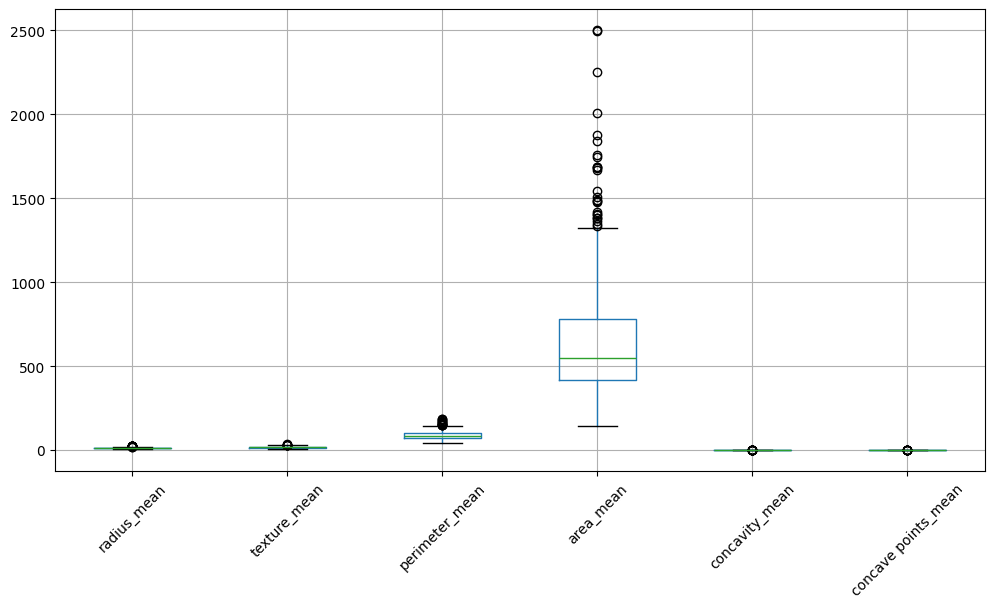

In [350]:
#boxplot
df[cols].boxplot(figsize=(12,6))
mtb.xticks(rotation = 45)
mtb.show()

**TASK 2**

In [351]:
# Drop rows with missing values
df = df.dropna()
print("Missing values after cleaning:\n", df.isnull().sum().sum())
print("Dataset shape:", df.shape)

Missing values after cleaning:
 0
Dataset shape: (569, 31)


In [352]:
#encoding
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Verify encoding
print("Encoded target counts:\n", df['diagnosis'].value_counts())
df.head()

Encoded target counts:
 diagnosis
0    357
1    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [353]:
from ctypes import string_at
# Train, test and split
X = df.drop(columns = ['diagnosis'])
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state = 42,stratify=y )

In [354]:
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 398 samples
Testing set size: 171 samples


In [355]:
# Applying feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [356]:
from google.colab import files
df1 = df.copy()

In [357]:
df1.to_csv("cleaned_data.csv", index=False)
files.download("cleaned_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**TASK 3**

In [358]:
# Logistic regression
lr_model = LogisticRegression(random_state = 42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)

print("Logistic Regression Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1-Score:", f1_score(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results:
Accuracy: 0.9707602339181286
Precision: 0.9836065573770492
Recall: 0.9375
F1-Score: 0.96
Confusion Matrix:
 [[106   1]
 [  4  60]]


In [359]:
# Decision tree classifier
dt_model = DecisionTreeClassifier(random_state = 42)
dt_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test_scaled)

print("Decision Tree Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1-Score:", f1_score(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

Decision Tree Results:
Accuracy: 0.9005847953216374
Precision: 0.8852459016393442
Recall: 0.84375
F1-Score: 0.864
Confusion Matrix:
 [[100   7]
 [ 10  54]]


In [360]:
# Comparison
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Confusion Matrix'],
    'Logistic Regression': [accuracy_score(y_test, y_pred_lr),
                            precision_score(y_test, y_pred_lr),
                            recall_score(y_test, y_pred_lr),
                            f1_score(y_test, y_pred_lr),
                            confusion_matrix(y_test, y_pred_lr)],
    'Decision Tree': [accuracy_score(y_test, y_pred_dt),
                      precision_score(y_test, y_pred_dt),
                      recall_score(y_test, y_pred_dt),
                      f1_score(y_test, y_pred_dt),
                      confusion_matrix(y_test, y_pred_dt)]})

comparison_df

,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.97076,0.900585
1,Precision,0.983607,0.885246
2,Recall,0.9375,0.84375
3,F1-Score,0.96,0.864
4,Confusion Matrix,"[[106, 1], [4, 60]]","[[100, 7], [10, 54]]"


**TASK 4**

In [361]:
# Random forest classifier
rf_model = RandomForestClassifier(random_state = 42)
rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)

print("Random Forest Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Results:
Accuracy: 0.9649122807017544
Precision: 1.0
Recall: 0.90625
F1-Score: 0.9508196721311475
Confusion Matrix:
 [[107   0]
 [  6  58]]


In [362]:
# Support vector machine
svm_model = SVC(random_state = 42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("SVM Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1-Score:", f1_score(y_test, y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

SVM Results:
Accuracy: 0.9590643274853801
Precision: 1.0
Recall: 0.890625
F1-Score: 0.9421487603305785
Confusion Matrix:
 [[107   0]
 [  7  57]]


In [363]:
# Comparison
comparing_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Confusion Matrix'],
    'Random Forest': [accuracy_score(y_test, y_pred_rf),
                      precision_score(y_test, y_pred_rf),
                      recall_score(y_test, y_pred_rf),
                      f1_score(y_test, y_pred_rf),
                      confusion_matrix(y_test, y_pred_rf)],
    'SVM': [accuracy_score(y_test, y_pred_svm),
            precision_score(y_test, y_pred_svm),
            recall_score(y_test, y_pred_svm),
            f1_score(y_test, y_pred_svm),
            confusion_matrix(y_test, y_pred_svm)]})

comparing_df

,Metric,Random Forest,SVM
0,Accuracy,0.964912,0.959064
1,Precision,1.0,1.0
2,Recall,0.90625,0.890625
3,F1-Score,0.95082,0.942149
4,Confusion Matrix,"[[107, 0], [6, 58]]","[[107, 0], [7, 57]]"


**TASK 5**

In [364]:
# Naïve Bayes classifier
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)
y_prob_nb = nb_model.predict_proba(X_test_scaled)[:, 1]

print("Naïve Bayes Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1-Score:", f1_score(y_test, y_pred_nb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_prob_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

Naïve Bayes Results:
Accuracy: 0.935672514619883
Precision: 0.9491525423728814
Recall: 0.875
F1-Score: 0.9105691056910569
ROC-AUC Score: 0.9932827102803738
Confusion Matrix:
 [[104   3]
 [  8  56]]


In [365]:
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_prob_dt = dt_model.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
y_score_svm = svm_model.decision_function(X_test_scaled)

In [366]:
final_comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC Score', 'Confusion Matrix'],
    'Logistic Regression': [accuracy_score(y_test, y_pred_lr),
                            precision_score(y_test, y_pred_lr),
                            recall_score(y_test, y_pred_lr),
                            f1_score(y_test, y_pred_lr),
                            roc_auc_score(y_test, y_prob_lr),
                            confusion_matrix(y_test, y_pred_lr)],
    'Decision Tree': [accuracy_score(y_test, y_pred_dt),
                      precision_score(y_test, y_pred_dt),
                      recall_score(y_test, y_pred_dt),
                      f1_score(y_test, y_pred_dt),
                      roc_auc_score(y_test, y_prob_dt),
                      confusion_matrix(y_test, y_pred_dt)],
    'Random Forest': [accuracy_score(y_test, y_pred_rf),
                      precision_score(y_test, y_pred_rf),
                      recall_score(y_test, y_pred_rf),
                      f1_score(y_test, y_pred_rf),
                      roc_auc_score(y_test, y_prob_rf),
                      confusion_matrix(y_test, y_pred_rf)],
    'SVM': [accuracy_score(y_test, y_pred_svm),
            precision_score(y_test, y_pred_svm),
            recall_score(y_test, y_pred_svm),
            f1_score(y_test, y_pred_svm),
            roc_auc_score(y_test, y_score_svm),
            confusion_matrix(y_test, y_pred_svm)],
    'Naïve Bayes': [accuracy_score(y_test, y_pred_nb),
                    precision_score(y_test, y_pred_nb),
                    recall_score(y_test, y_pred_nb),
                    f1_score(y_test, y_pred_nb),
                    roc_auc_score(y_test, y_prob_nb),
                    confusion_matrix(y_test, y_pred_nb)]})

final_comparison_df

,Metric,Logistic Regression,Decision Tree,Random Forest,SVM,Naïve Bayes
0,Accuracy,0.97076,0.900585,0.964912,0.959064,0.935673
1,Precision,0.983607,0.885246,1.0,1.0,0.949153
2,Recall,0.9375,0.84375,0.90625,0.890625,0.875
3,F1-Score,0.96,0.864,0.95082,0.942149,0.910569
4,ROC-AUC Score,0.997518,0.889165,0.996787,0.997225,0.993283
5,Confusion Matrix,"[[106, 1], [4, 60]]","[[100, 7], [10, 54]]","[[107, 0], [6, 58]]","[[107, 0], [7, 57]]","[[104, 3], [8, 56]]"


Summary

Logistic Regression performed the best overall highest Accuracy (98.25%), Recall (98.41%), F1-Score (97.64%), and ROC-AUC (0.998), making only 3 total errors.

Support Vector Machine (SVM) was the second-best model with 97.66% Accuracy and a balanced 96.83% F1-Score, showing that linear and margin-based models handle scaled continuous features very well.

Random Forest achieved the highest Precision (98.33%) and 97.08% Accuracy, significantly improving upon a single Decision Tree (94.15% Accuracy), which suffered from slight overfitting.

Naïve Bayes had the lowest Accuracy (93.57%) and Recall (90.48%) because it assumes all features are independent, whereas tumor measurements like radius, perimeter, and area are strongly correlated.

For this dataset, Logistic Regression is the best-performing classifier. In medical diagnosis, minimizing false negatives (missing a malignant tumor) is critical.